# 04 EDA, Tests und Karten

- Teil 1: EDA (4.1)
- Teil 2: EDA (4.2)
- Teil 3: Statistische Tests (4.4)
- Teil 4: Karten (4.3)

In [1]:
import os
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

pd.set_option("display.max_colwidth", None)
panel = pd.read_csv("../data/processed/panel_winter.csv")
d = panel[panel.covid == 0].copy()          # ohne Covid-Winter
KLASSEN = ["tief", "mittel", "hoch"]

# Einheitlicher Stil für alle Grafiken (Teil 2 und 3)
FARBEN = {"tief": "#d1342f", "mittel": "#e3a21a", "hoch": "#1f6fd1"}   # Höhenklassen, überall gleich
QUELLE = "Daten: BFS HESTA, Open-Meteo (ERA5)"
MONATE = {12: "Dez", 1: "Jan", 2: "Feb", 3: "Mär"}
sns.set_theme(style="whitegrid", rc={"axes.titleweight": "bold", "grid.color": "#e6e6e6"})

def speichern(fig, name, quelle=QUELLE):
    """Quelle unten links anfügen und als figures/<name>.png (dpi 200) speichern."""
    fig.text(0.01, 0.01, quelle, fontsize=8, color="grey")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(f"../figures/{name}.png", dpi=200)
print(len(d), "Monatsbeobachtungen,", d.bfs_nr.nunique(), "Orte")

2032 Monatsbeobachtungen, 45 Orte


## Teil 1: Kennzahlen (4.1)

Nicht-grafische EDA: Wie sehen die Daten aus, und wo liegen Probleme? Grundlage ist das Panel aus der Setup-Zelle (`panel`, 2'255 Ortsmonate, identisch mit der PostgreSQL-View `v_panel_winter`) bzw. `d` ohne Covid-Monate (2'032). Für die Zusatz-Variablen aus 1.7 wird `kontext_monat.csv` über Jahr und Monat angehängt.

### 1.1 Überblick: Spalten, Datentypen, fehlende Werte

In [2]:
panel.info()

<class 'pandas.DataFrame'>
RangeIndex: 2255 entries, 0 to 2254
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   bfs_nr             2255 non-null   int64  
 1   jahr               2255 non-null   int64  
 2   monat              2255 non-null   int64  
 3   betten             2255 non-null   float64
 4   bettenauslastung   2255 non-null   float64
 5   logiernaechte      2255 non-null   float64
 6   zimmer             2255 non-null   float64
 7   zimmerauslastung   2255 non-null   float64
 8   zimmernaechte      2255 non-null   float64
 9   winter             2255 non-null   int64  
 10  winter_label       2255 non-null   str    
 11  covid              2255 non-null   int64  
 12  ostern_im_monat    2255 non-null   int64  
 13  ln_total           2255 non-null   float64
 14  ln_schweiz         2255 non-null   float64
 15  ln_ausland         2255 non-null   float64
 16  anteil_ausland     2255 non-null   

30 Spalten, 2'255 Zeilen. Die Kennzahlen sind numerisch (BFS-Werte als float, weil sie über JSON kommen), Name, Kanton, Höhenklassen und Winterlabel sind Text. `covid` und `ostern_im_monat` sind 0/1-Dummies, `korrigiert` markiert Orte mit manueller Korrektur aus 1.3.

In [3]:
fehlend = panel.isna().sum()
print("Fehlende Werte im Panel insgesamt:", fehlend.sum())
fehlend[fehlend > 0]

Fehlende Werte im Panel insgesamt: 0


Series([], dtype: int64)

Das Panel hat keine fehlenden Werte. Die Zielgrösse, Herkunft und Wetter sind vollständig, weil Monate mit vertraulichen BFS-Werten schon in 3.1 entfernt wurden. In der ersten Fassung dieser EDA fehlte noch bei 469 Zeilen (10 Orten) der Kanton. Das ist inzwischen behoben (siehe 1.2).

In [4]:
panel.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
bfs_nr,2255.0,3930.9,1755.0,561.0,3359.0,3786.0,5841.0,6300.0
jahr,2255.0,2019.9,3.7,2013.0,2017.0,2020.0,2023.0,2026.0
monat,2255.0,4.5,4.4,1.0,1.0,2.0,3.0,12.0
betten,2255.0,1526.6,1584.2,122.0,511.0,1068.0,1873.0,7629.0
bettenauslastung,2255.0,46.3,17.0,7.0,34.0,46.0,58.0,108.0
logiernaechte,2255.0,23298.7,30385.8,408.0,5184.0,13169.0,27889.5,194202.0
zimmer,2255.0,726.5,802.7,50.0,236.0,465.0,833.0,3752.0
zimmerauslastung,2255.0,53.5,17.3,10.0,41.0,54.0,66.0,94.0
zimmernaechte,2255.0,12613.7,16647.0,223.0,2843.5,6975.0,14803.0,97870.0
winter,2255.0,2019.1,3.7,2013.0,2016.0,2019.0,2022.0,2025.0


Die Zimmerauslastung liegt zwischen 10 und 94 % (Median 54 %). Es gibt also keine Monate mit 0 %. Auffällig: Die Bettenauslastung erreicht einmal 108 % (Leysin, Februar 2017). Über 100 % ist möglich, wenn Zusatzbetten belegt werden, der Wert ist also plausibel und bleibt drin. `ln_total` (Herkunftstabelle) und `logiernaechte` (Haupttabelle) sind bis auf 3 Zeilen identisch, also dieselbe Grösse aus zwei BFS-Tabellen. Betten, Logiernächte und Zimmernächte sind stark rechtsschief (Mittel deutlich über dem Median): Wenige grosse Orte (z. B. Davos, Zermatt, St. Moritz) haben ein Vielfaches der kleinen. Für die Regression spricht das für Logarithmen oder Anteile statt absoluter Zahlen.

### 1.2 Orte, Kantone und Beobachtungen pro Ort

**Behobenes Datenproblem:** Diese EDA hat gezeigt, dass der Kanton aus dem Geocoding (Notebook 01, Abschnitt 3) unzuverlässig war. Bei 10 der 45 Orte fehlte er, alle manuell korrigiert (`korrigiert = True`, meist Fusionsgemeinden), und Hasliberg (BE) stand als «Kanton Zürich» drin. Über alle 186 BFS-Gemeinden waren 26 betroffen. Seit der Korrektur kommt der Kanton in Notebook 01, Abschnitt 5, aus den amtlichen Gemeindegrenzen (swissBOUNDARIES3D) und steht als Kürzel (BE, GR, …) in der Tabelle. `gemeinden.csv`, das Panel (3.2) und die Datenbank (3.4) sind danach neu erzeugt.

In [5]:
orte_eda = (panel.drop_duplicates("bfs_nr")
            [["bfs_nr", "name", "kanton", "hoehe_m", "hoehenklasse", "hoehenklasse_1000", "korrigiert"]]
            .rename(columns={"kanton": "kt"}))
assert len(orte_eda) == 45 and orte_eda.kt.notna().all()
orte_eda[orte_eda.bfs_nr.isin([783, 1631, 3543, 6037])][["bfs_nr", "name", "kt", "korrigiert"]]   # Stichprobe korrigierter Orte

,bfs_nr,name,kt,korrigiert
104,1631,Glarus Süd,GL,True
364,3543,Surses,GR,True
1634,6037,Val de Bagnes,VS,True
2099,783,Hasliberg,BE,True


In [6]:
pd.crosstab(orte_eda.kt, orte_eda.hoehenklasse, margins=True, margins_name="Total")[KLASSEN + ["Total"]]

hoehenklasse,tief,mittel,hoch,Total
kt,,,,
BE,3,2,0,5
GL,1,0,0,1
GR,3,9,7,19
OW,1,0,0,1
SG,2,1,0,3
UR,0,1,0,1
VD,2,2,0,4
VS,1,4,6,11
Total,13,19,13,45


Die 45 Orte verteilen sich 13 / 19 / 13 auf tief / mittel / hoch. Graubünden (19) und Wallis (11) stellen zusammen zwei Drittel der Orte, und alle 13 hohen Orte liegen dort. Höhenklasse und Kanton sind also nicht unabhängig: Ein Unterschied zwischen den Höhenklassen kann auch ein Unterschied zwischen GR/VS und dem Rest sein (z. B. Bekanntheit, internationale Gäste).

In [7]:
pd.crosstab(orte_eda.hoehenklasse, orte_eda.hoehenklasse_1000, margins=True, margins_name="Total").reindex(
    index=KLASSEN + ["Total"], columns=KLASSEN + ["Total"])

hoehenklasse_1000,tief,mittel,hoch,Total
hoehenklasse,,,,
tief,3,10,0,13
mittel,0,19,0,19
hoch,0,0,13,13
Total,3,29,13,45


In [8]:
orte_eda.sort_values("hoehe_m")[["name", "kt", "hoehe_m", "hoehenklasse", "hoehenklasse_1000"]].head(14)

,name,kt,hoehe_m,hoehenklasse,hoehenklasse_1000
208,Quarten,SG,574.0,tief,tief
1530,Château-d'Oex,VD,962.0,tief,tief
104,Glarus Süd,GL,977.0,tief,tief
407,Laax,GR,1011.0,tief,mittel
52,Engelberg,OW,1015.0,tief,mittel
1800,Champéry,VS,1048.0,tief,mittel
2203,Saanen,BE,1055.0,tief,mittel
2151,Lenk,BE,1067.0,tief,mittel
594,Flims,GR,1085.0,tief,mittel
260,Wildhaus-Alt St. Johann,SG,1090.0,tief,mittel


**Warum die Grenze bei 1200 m liegt:** Mit einer Grenze bei 1000 m wären nur 3 Orte «tief» (3 / 29 / 13). Mit drei Orten lässt sich kein Gruppenvergleich rechnen, und die mittlere Klasse wäre ein Sammeltopf. Bei 1200 m sind die Klassen ausgewogen (13 / 19 / 13). Die 10 Orte zwischen 1000 und 1200 m wechseln von «mittel» nach «tief», die hohe Klasse (ab 1500 m) bleibt gleich.

In [9]:
n_monate = panel.groupby(["bfs_nr", "name"]).agg(monate=("monat", "size"), erster_winter=("winter_label", "min"))
n_monate[n_monate.monate < n_monate.monate.max()]

,,monate,erster_winter
bfs_nr,name,,
3543,Surses,43,2015/16
3714,Rheinwald,31,2018/19
6037,Val de Bagnes,23,2020/21
6077,Goms,39,2016/17
6253,Crans-Montana,39,2016/17


40 Orte haben alle 52 Wintermonate (13 Winter × 4 Monate). 5 Orte beginnen später, weil sie durch Gemeindefusionen entstanden sind und das BFS sie erst ab der Fusion führt (z. B. Val de Bagnes erst ab 2020/21). Das Panel ist also **unbalanciert**. Für Vergleiche pro Ort ist das unproblematisch, bei Mittelwerten pro Winter verschiebt sich aber die Zusammensetzung leicht (1.4).

### 1.3 Corona-Monate

Als Corona-Monate gelten März 2020 (Lockdown ab 16.3.) und der ganze Winter 2020/21 (`covid = 1`). Sie werden hier getrennt ausgewiesen und für alle weiteren Kennzahlen weggelassen (`d`).

In [10]:
cov = (panel.groupby(["covid", "winter_label"])
       .agg(Monate=("zimmerauslastung", "size"), Mittel=("zimmerauslastung", "mean"), Median=("zimmerauslastung", "median"))
       .round(1))
cov.loc[1]

,Monate,Mittel,Median
winter_label,,,
2019/20,44,33.1,30.0
2020/21,179,44.6,44.0


In [11]:
panel.groupby("covid")["zimmerauslastung"].agg(Monate="size", Mittel="mean", Median="median", Std="std").round(1)

,Monate,Mittel,Median,Std
covid,,,,
0,2032,54.8,55.0,16.8
1,223,42.4,41.0,17.4


223 Ortsmonate sind Corona-Monate. Im März 2020 fällt die Auslastung massiv ab, im Winter 2020/21 (Skigebiete offen, aber Restaurants zu und kaum ausländische Gäste) ist sie im Mittel rund 10 pp tiefer als in normalen Wintern. Diese Monate würden jeden Schnee-Effekt überdecken, darum gehen sie nicht in die Kennzahlen ein. Es bleiben 2'032 Ortsmonate.

### 1.4 Zimmerauslastung pro Höhenklasse und Winter

Mittelwert und Median **pro Ort über alle Winter** stehen bereits in Teil 3.1 (47.9 / 53.0 / 64.0 % für tief / mittel / hoch). Hier deshalb nur die Aufteilung nach Winter und nach Monat.

In [12]:
pro_winter = (d.groupby(["winter_label", "hoehenklasse"])["zimmerauslastung"]
              .agg(["mean", "median"]).unstack("hoehenklasse").round(1))
pro_winter.columns = [f"{'Mittel' if s == 'mean' else 'Median'} {k}" for s, k in pro_winter.columns]
pro_winter[[f"{s} {k}" for s in ["Mittel", "Median"] for k in KLASSEN]]

,Mittel tief,Mittel mittel,Mittel hoch,Median tief,Median mittel,Median hoch
winter_label,,,,,,
2013/14,47.0,56.0,63.4,49.0,55.5,65.5
2014/15,46.4,52.9,63.2,45.5,53.0,61.5
2015/16,45.7,51.1,59.6,46.5,51.0,59.5
2016/17,43.8,49.8,60.2,43.0,50.0,59.0
2017/18,46.0,53.7,63.6,47.0,54.0,65.5
2018/19,46.7,53.1,63.3,45.0,54.0,64.0
2019/20,50.9,55.8,66.0,48.0,57.0,67.0
2021/22,49.8,57.1,63.5,47.5,57.0,65.5
2022/23,49.3,54.8,65.9,49.0,55.0,66.5


In jedem Winter ist «hoch» klar vorne (rund 14–17 pp vor «tief»), die Reihenfolge tief < mittel < hoch hält in allen Wintern, 2025/26 liegen tief und mittel aber gleichauf. Mittel und Median liegen nahe beieinander, die Verteilung innerhalb der Klassen ist kaum schief. Über die Zeit steigen «tief» (von rund 46 auf 50 %) und «hoch» (von rund 63 auf 66 %) leicht, «mittel» nicht. 2019/20 ist nicht vergleichbar: Ohne den Corona-März zählen nur Dezember bis Februar, der schwache März fehlt. Für die Regression heisst das: Winter als Kontrolle (fixe Effekte oder Trend) aufnehmen.

In [13]:
pro_monat = d.pivot_table(index="monat", columns="hoehenklasse", values="zimmerauslastung", aggfunc="mean")[KLASSEN]
pro_monat.index = pro_monat.index.map({12: "Dez", 1: "Jan", 2: "Feb", 3: "Mär"})
pro_monat.reindex(["Dez", "Jan", "Feb", "Mär"]).round(1)

hoehenklasse,tief,mittel,hoch
monat,,,
Dez,38.9,44.1,55.4
Jan,47.8,53.3,62.2
Feb,61.3,66.7,75.1
Mär,43.4,49.1,63.1


Der Kalender ist ein starker Faktor: Dezember ist in allen Klassen am schwächsten (Zwischensaison bis Weihnachten), Februar am stärksten (Sportferien). Bei den hohen Orten bleibt der März hoch, bei den tiefen fällt er ab, vermutlich weil dort der Schnee im Frühling fehlt.

### 1.5 Ausreisser

Monate mit sehr tiefer Auslastung werden nicht gelöscht, sondern erst geprüft.

In [14]:
tief = d[d.zimmerauslastung <= 20]
print(len(tief), "Ortsmonate mit ≤ 20 % Auslastung, davon im Dezember:", (tief.monat == 12).sum())
tief.sort_values("zimmerauslastung")[["name", "hoehenklasse", "winter_label", "monat", "zimmerauslastung", "betten"]].head(10)

28 Ortsmonate mit ≤ 20 % Auslastung, davon im Dezember: 15


,name,hoehenklasse,winter_label,monat,zimmerauslastung,betten
365,Surses,mittel,2016/17,12,12.0,1088.0
1530,Château-d'Oex,tief,2013/14,12,15.0,220.0
959,Bregaglia,tief,2013/14,1,15.0,1221.0
964,Bregaglia,tief,2015/16,12,15.0,999.0
118,Glarus Süd,tief,2017/18,12,15.0,822.0
114,Glarus Süd,tief,2016/17,12,16.0,824.0
958,Bregaglia,tief,2013/14,12,16.0,813.0
106,Glarus Süd,tief,2014/15,12,16.0,774.0
122,Glarus Süd,tief,2018/19,12,17.0,798.0
369,Surses,mittel,2017/18,12,17.0,1072.0


Es gibt keine 0-%-Monate. Die 28 Monate mit höchstens 20 % liegen fast alle an den Saisonrändern (15 im Dezember, 6 im März) und betreffen wenige kleine Orte, vor allem Glarus Süd, Bregaglia und Surses. Vermutlich ist das Zwischensaison (Bergbahnen erst ab Weihnachten offen bzw. Saisonende), kein Datenfehler. Die Werte bleiben drin, die Monats-Bereinigung in 1.7 fängt diesen Effekt auf.

### 1.6 Zusatz-Variablen aus 1.7

Wechselkurs EUR/CHF, Schulferien DE und CH sowie Feiertage CH gelten für alle Orte gleich und werden über Jahr und Monat angehängt.

In [15]:
kontext = pd.read_csv("../data/processed/kontext_monat.csv")
dk = d.merge(kontext, on=["jahr", "monat"], how="left", validate="many_to_one")
assert len(dk) == len(d) and dk[kontext.columns].notna().all().all()

annahme = (dk.drop_duplicates(["jahr", "monat"])
           .assign(Status=lambda x: np.select([x.ferientage_ch_annahme == 1, x.ferientage_ch_annahme == 0],
                                              ["geschätzt (Annahme)", "echte Daten"], "teilweise geschätzt"))
           .groupby("winter_label")
           .agg(Monate=("monat", "size"), Anteil_geschätzt=("ferientage_ch_annahme", "mean"),
                ferientage_ch=("ferientage_ch", "mean"), Status=("Status", lambda s: ", ".join(sorted(set(s))))))
annahme.round(2)

,Monate,Anteil_geschätzt,ferientage_ch,Status
winter_label,,,,
2013/14,4,1.00,6.22,geschätzt (Annahme)
2014/15,4,1.00,6.28,geschätzt (Annahme)
2015/16,4,1.00,7.70,geschätzt (Annahme)
2016/17,4,1.00,6.05,geschätzt (Annahme)
2017/18,4,1.00,6.10,geschätzt (Annahme)
2018/19,4,1.00,6.12,geschätzt (Annahme)
2019/20,3,0.64,8.30,teilweise geschätzt
2021/22,4,0.00,6.18,echte Daten
2022/23,4,0.00,6.18,echte Daten


**⚠ `ferientage_ch` ist bis 2018/19 vollständig geschätzt** (Annahme aus dem Muster 2021–2026, siehe docs/features.md). Im Winter 2019/20 sind Dezember bis Februar teilweise geschätzt (Übergang), ab 2021/22 sind es echte Daten. Weil die geschätzten Werte jedes Jahr dasselbe Wochenmuster wiederholen, ändert sich `ferientage_ch` vor 2019 kaum von Winter zu Winter (kleine Unterschiede nur durch die Lage der Kalenderwochen). Echte Veränderungen, z. B. verschobene Sportferien, kann die Variable dort nicht zeigen. Ergebnisse mit dieser Variable müssen in der Präsentation als Annahme gekennzeichnet werden.

In [16]:
dk[["eur_chf", "ferientage_de", "ferientage_ch", "feiertage_ch"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
eur_chf,2032.0,1.06,0.09,0.91,0.97,1.07,1.13,1.23
ferientage_de,2032.0,5.45,2.84,1.10,3.40,4.80,8.80,10.60
ferientage_ch,2032.0,6.48,2.68,1.10,4.30,6.90,8.40,12.40
feiertage_ch,2032.0,0.98,0.82,0.00,0.00,1.40,1.90,2.10


Der Wechselkurs bewegt sich zwischen 0.91 und 1.23 CHF pro EUR (Aufhebung des Mindestkurses im Januar 2015, danach weitere Aufwertung des Frankens). Schulferien gibt es im Wintermonat im Mittel rund 5–6 Tage (DE) bzw. 6–7 Tage (CH), mit starkem Muster (Weihnachten, Sportferien im Februar).

### 1.7 Korrelationsmatrix

Alle numerischen Variablen ausser IDs und Dummies (`bfs_nr`, `monat`, `winter`, `covid`, Koordinaten). Zwei Varianten wie in Teil 3.4:

1. **Roh:** Monatswerte direkt. Misst stark den Kalender (Januar am meisten Schnee, Februar höchste Auslastung) und die Grösse der Orte.
2. **Bereinigt um Ort × Monat:** Von jeder Variable wird der Mittelwert derselben Gemeinde im selben Kalendermonat abgezogen. Übrig bleibt die Abweichung vom Üblichen. Ortsfeste Grössen (`hoehe_m`, `winteranteil`) sind danach überall 0 und fallen weg.

Pearson-Korrelation, Werte mit |r| > 0.7 gelten als Kandidaten für Multikollinearität in 5.2.

In [17]:
num = ["zimmerauslastung", "bettenauslastung", "betten", "zimmer", "logiernaechte", "zimmernaechte",
       "ln_total", "ln_schweiz", "ln_ausland", "anteil_ausland",
       "temp_mittel", "schneefall_cm", "niederschlag_mm", "schneetage",
       "hoehe_m", "winteranteil", "jahr", "ostern_im_monat",
       "eur_chf", "ferientage_de", "ferientage_ch", "feiertage_ch"]

kor_roh = dk[num].corr()
kor_roh.round(2).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1).format("{:.2f}")

,zimmerauslastung,bettenauslastung,betten,zimmer,logiernaechte,zimmernaechte,ln_total,ln_schweiz,ln_ausland,anteil_ausland,temp_mittel,schneefall_cm,niederschlag_mm,schneetage,hoehe_m,winteranteil,jahr,ostern_im_monat,eur_chf,ferientage_de,ferientage_ch,feiertage_ch
zimmerauslastung,1.00,0.96,0.39,0.37,0.51,0.48,0.51,0.51,0.45,0.28,-0.20,0.13,-0.11,0.18,0.39,0.41,0.10,-0.04,-0.06,-0.28,-0.04,-0.37
bettenauslastung,0.96,1.00,0.40,0.39,0.53,0.50,0.53,0.54,0.47,0.24,-0.18,0.12,-0.10,0.17,0.38,0.35,0.12,-0.06,-0.08,-0.27,-0.00,-0.39
betten,0.39,0.40,1.00,1.00,0.96,0.97,0.96,0.92,0.88,0.37,-0.19,0.10,-0.10,0.17,0.37,0.15,-0.03,0.00,0.02,-0.00,-0.00,-0.00
zimmer,0.37,0.39,1.00,1.00,0.95,0.97,0.95,0.92,0.88,0.35,-0.20,0.11,-0.10,0.18,0.38,0.14,-0.03,0.00,0.03,0.00,-0.00,-0.00
logiernaechte,0.51,0.53,0.96,0.95,1.00,0.99,1.00,0.93,0.95,0.37,-0.19,0.12,-0.11,0.18,0.39,0.18,0.02,0.00,-0.01,-0.08,-0.03,-0.09
zimmernaechte,0.48,0.50,0.97,0.97,0.99,1.00,0.99,0.93,0.94,0.36,-0.20,0.12,-0.10,0.19,0.41,0.17,-0.00,0.01,0.01,-0.07,-0.04,-0.07
ln_total,0.51,0.53,0.96,0.95,1.00,0.99,1.00,0.93,0.95,0.37,-0.19,0.12,-0.11,0.18,0.39,0.18,0.02,0.00,-0.01,-0.08,-0.03,-0.09
ln_schweiz,0.51,0.54,0.92,0.92,0.93,0.93,0.93,1.00,0.76,0.16,-0.18,0.09,-0.12,0.15,0.38,0.21,0.05,-0.01,-0.03,-0.11,-0.03,-0.12
ln_ausland,0.45,0.47,0.88,0.88,0.95,0.94,0.95,0.76,1.00,0.51,-0.17,0.13,-0.08,0.18,0.36,0.13,-0.01,0.01,0.01,-0.05,-0.02,-0.05
anteil_ausland,0.28,0.24,0.37,0.35,0.37,0.36,0.37,0.16,0.51,1.00,-0.08,0.07,-0.03,0.11,0.18,0.13,-0.18,0.02,0.15,0.06,0.03,0.05


In [18]:
ortsfest = ["hoehe_m", "winteranteil"]
num_ber = [c for c in num if c not in ortsfest]
dk_ber = dk[num_ber] - dk.groupby(["bfs_nr", "monat"])[num_ber].transform("mean")
kor_ber = dk_ber.corr()
kor_ber.round(2).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1).format("{:.2f}")

,zimmerauslastung,bettenauslastung,betten,zimmer,logiernaechte,zimmernaechte,ln_total,ln_schweiz,ln_ausland,anteil_ausland,temp_mittel,schneefall_cm,niederschlag_mm,schneetage,jahr,ostern_im_monat,eur_chf,ferientage_de,ferientage_ch,feiertage_ch
zimmerauslastung,1.00,0.88,-0.16,-0.17,0.43,0.47,0.43,0.32,0.27,-0.00,0.04,-0.09,-0.07,-0.08,0.20,0.03,-0.12,-0.01,0.05,0.03
bettenauslastung,0.88,1.00,-0.24,-0.17,0.47,0.41,0.47,0.33,0.30,0.01,0.08,-0.12,-0.07,-0.12,0.25,0.02,-0.18,-0.02,0.07,0.02
betten,-0.16,-0.24,1.00,0.88,0.39,0.43,0.39,0.26,0.27,0.17,-0.07,0.07,0.01,0.06,-0.14,0.02,0.14,0.02,-0.00,0.02
zimmer,-0.17,-0.17,0.88,1.00,0.31,0.43,0.31,0.17,0.24,0.22,-0.11,0.09,0.02,0.08,-0.27,0.03,0.26,0.03,0.01,0.03
logiernaechte,0.43,0.47,0.39,0.31,1.00,0.90,1.00,0.54,0.77,0.13,0.06,-0.04,-0.03,-0.03,0.15,0.05,-0.09,0.03,0.06,0.05
zimmernaechte,0.47,0.41,0.43,0.43,0.90,1.00,0.90,0.50,0.68,0.17,-0.00,0.01,-0.02,0.02,-0.01,0.05,0.06,0.04,0.07,0.06
ln_total,0.43,0.47,0.39,0.31,1.00,0.90,1.00,0.54,0.77,0.13,0.06,-0.04,-0.03,-0.03,0.15,0.05,-0.09,0.03,0.06,0.05
ln_schweiz,0.32,0.33,0.26,0.17,0.54,0.50,0.54,1.00,-0.12,-0.40,0.05,-0.13,-0.07,-0.15,0.31,0.02,-0.23,-0.03,0.04,0.01
ln_ausland,0.27,0.30,0.27,0.24,0.77,0.68,0.77,-0.12,1.00,0.46,0.03,0.05,0.02,0.07,-0.06,0.04,0.07,0.05,0.04,0.05
anteil_ausland,-0.00,0.01,0.17,0.22,0.13,0.17,0.13,-0.40,0.46,1.00,-0.02,0.11,0.04,0.12,-0.42,0.04,0.36,0.08,0.07,0.05


In [19]:
def starke_paare(k, schwelle=0.7):
    oben = k.where(np.triu(np.ones(k.shape, dtype=bool), k=1)).stack()
    return oben[oben.abs() > schwelle]

idx = starke_paare(kor_roh).index.union(starke_paare(kor_ber).index)
paare = pd.DataFrame({"r roh": kor_roh.stack().reindex(idx), "r bereinigt": kor_ber.stack().reindex(idx)})
paare.sort_values("r roh", key=abs, ascending=False).round(2)

r roh  r bereinigt
logiernaechte    ln_total           1.00         1.00
betten           zimmer             1.00         0.88
zimmernaechte    ln_total           0.99         0.90
logiernaechte    zimmernaechte      0.99         0.90
zimmer           zimmernaechte      0.97         0.43
betten           zimmernaechte      0.97         0.43
                 ln_total           0.96         0.39
                 logiernaechte      0.96         0.39
zimmerauslastung bettenauslastung   0.96         0.88
zimmer           ln_total           0.95         0.31
                 logiernaechte      0.95         0.31
logiernaechte    ln_ausland         0.95         0.77
ln_total         ln_ausland         0.95         0.77
zimmernaechte    ln_ausland         0.94         0.68
ln_total         ln_schweiz         0.93         0.54
logiernaechte    ln_schweiz         0.93         0.54
zimmernaechte    ln_schweiz         0.93         0.50
betten           ln_schweiz         0.92         0.26
zimmer           ln_schweiz         0.92         0.17
jahr             eur_chf           -0.89        -0.88
betten           ln_ausland         0.88         0.27
zimmer           ln_ausland         0.88         0.24
schneefall_cm    schneetage         0.87         0.84
ferientage_de    feiertage_ch       0.85         0.91
ln_schweiz       ln_ausland         0.76        -0.12
ostern_im_monat  ferientage_de      0.20         0.92
                 feiertage_ch       0.12         0.93

**Kandidaten für Multikollinearität (|r| > 0.7) in 5.2:**

- **Grösse des Orts:** Betten, Zimmer, Logiernächte, Zimmernächte und Logiernächte nach Herkunft korrelieren roh mit 0.9 bis 1.0. Sie messen alle die Grösse des Orts. `logiernaechte` und `ln_total` sind praktisch identisch (r = 1.00). Ins Modell höchstens eine Grössenvariable (z. B. log Betten), und keine, die aus der Zielgrösse mitberechnet ist (Zimmernächte).
- **`bettenauslastung` und `zimmerauslastung`** (0.96 / 0.88) sind zwei Varianten der Zielgrösse, `bettenauslastung` darf kein Prädiktor sein.
- **`jahr` und `eur_chf`** (−0.89 / −0.88): Der Franken wurde fast stetig stärker. Ein Zeittrend und der Wechselkurs lassen sich im Modell kaum trennen.
- **`schneefall_cm` und `schneetage`** (0.87 / 0.84): beide messen Schnee, nur eine davon verwenden.
- **Ostern, Ferien DE und Feiertage CH:** roh 0.85 zwischen `ferientage_de` und `feiertage_ch`, bereinigt um Ort × Monat über 0.9 mit `ostern_im_monat`. Fällt Ostern in den März, gibt es dort Osterferien und Karfreitag. Die drei Variablen erfassen dann fast dasselbe Ereignis.
- `ln_schweiz` und `ln_ausland` korrelieren roh mit 0.76, bereinigt nicht mehr (−0.12). Das ist nur der Grösseneffekt, keine echte Redundanz.

In [20]:
# Zusammenhänge mit der Zielgrösse, roh vs. bereinigt
ziel = pd.DataFrame({"r roh": kor_roh["zimmerauslastung"], "r bereinigt": kor_ber["zimmerauslastung"]}).drop("zimmerauslastung")
ziel.sort_values("r bereinigt", key=abs, ascending=False).round(2)

,r roh,r bereinigt
bettenauslastung,0.96,0.88
zimmernaechte,0.48,0.47
ln_total,0.51,0.43
logiernaechte,0.51,0.43
ln_schweiz,0.51,0.32
ln_ausland,0.45,0.27
jahr,0.10,0.20
zimmer,0.37,-0.17
betten,0.39,-0.16
eur_chf,-0.06,-0.12


Roh hängen mit der Auslastung vor allem Ortseigenschaften zusammen: Höhe (0.39), Winteranteil (0.41), Grösse und Ausländeranteil (0.28). Bereinigt um Ort × Monat fallen diese weg. Was bleibt, ist schwach: Der Trend über die Jahre (0.20) ist am stärksten, Schneefall und Schneetage sind leicht negativ (−0.09 / −0.08, wie in Teil 3.4), Ferien und Feiertage liegen bei 0. Ihre rohen Korrelationen (z. B. Feiertage −0.37) entstehen also nur über den Kalender: Der Dezember hat viele Feiertage, aber eine tiefe Auslastung. Logier- und Zimmernächte korrelieren auch bereinigt deutlich, sie sind aber Teil der Zielgrösse selbst und keine Erklärung.

## Teil 2: Grafiken (4.2)

Grundlage ist dasselbe Panel wie in Teil 1 (identisch mit der View `v_panel_winter`, 45 Orte). Corona-Monate (März 2020, Winter 2020/21) sind in den Verlaufsgrafiken markiert und sonst weggelassen (`d`).

**Einheitlicher Stil:** Höhenklassen immer in denselben Farben (tief rot, mittel orange, hoch blau, `FARBEN` in der Setup-Zelle), auch im Boxplot in Teil 3. Für Werte auf einer Skala (Heatmap, Karte in Teil 4) gilt die Blau-Skala `Blues`. Jede Grafik hat Titel, Achsen mit Einheit und Quelle und liegt als PNG (dpi 200) in `figures/`.

Der Boxplot Auslastung nach Höhenklasse (mit Einzelpunkten pro Ort) steht in Teil 3.1 und wird hier nicht wiederholt.

### 2.1 Verteilung der Zimmerauslastung

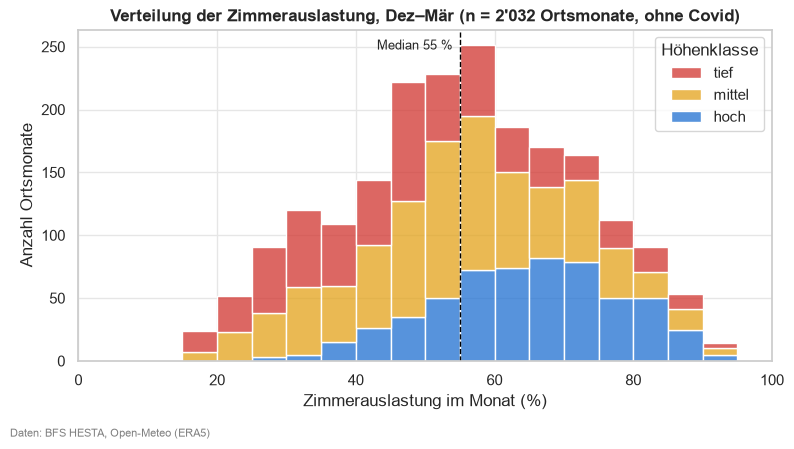

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=d, x="zimmerauslastung", hue="hoehenklasse", hue_order=KLASSEN, palette=FARBEN,
             multiple="stack", binwidth=5, binrange=(0, 100), edgecolor="white", linewidth=1, ax=ax)
med = d.zimmerauslastung.median()
ax.axvline(med, color="black", linestyle="--", linewidth=1)
ax.text(med - 1, ax.get_ylim()[1] * 0.97, f"Median {med:.0f} %", fontsize=9, va="top", ha="right")
ax.set(xlim=(0, 100), xlabel="Zimmerauslastung im Monat (%)", ylabel="Anzahl Ortsmonate",
       title=f"Verteilung der Zimmerauslastung, Dez–Mär (n = {len(d):,} Ortsmonate, ohne Covid)".replace(f"{len(d):,}", f"{len(d):,}".replace(",", "'")))
ax.get_legend().set_title("Höhenklasse")
speichern(fig, "hist_auslastung")
plt.show()

Die Auslastung ist breit verteilt, mit einem Gipfel um 50–65 % und ohne Häufung bei 0 oder 100 %. Die Klassen liegen übereinander verschoben: Die tiefen Orte (rot) liegen eher links, die hohen (blau) eher rechts: Obwohl sie nur 13 der 45 Orte sind, stellen sie rund die Hälfte der Monate mit über 70 % Auslastung. Die Verteilung ist annähernd symmetrisch, für die Regression ist darum keine Transformation der Zielgrösse nötig.

### 2.2 Auslastung pro Monat und Höhenklasse

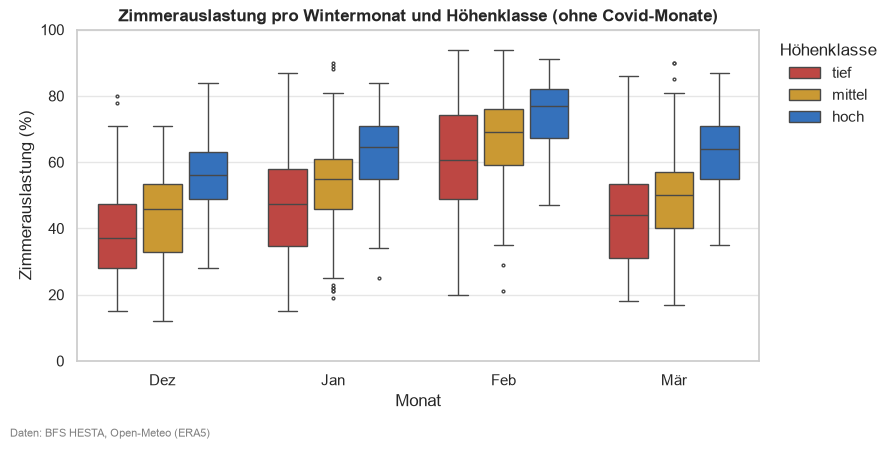

In [22]:
dm = d.assign(Monat=d.monat.map(MONATE))
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=dm, x="Monat", y="zimmerauslastung", hue="hoehenklasse", order=list(MONATE.values()),
            hue_order=KLASSEN, palette=FARBEN, fliersize=2, linewidth=1, gap=0.15, ax=ax)
ax.set(ylim=(0, 100), xlabel="Monat", ylabel="Zimmerauslastung (%)",
       title="Zimmerauslastung pro Wintermonat und Höhenklasse (ohne Covid-Monate)")
ax.legend(title="Höhenklasse", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
speichern(fig, "box_monat_hoehe")
plt.show()

In jedem Monat gilt tief < mittel < hoch. Der Kalender wirkt aber mindestens so stark wie die Höhe: Im Februar (Sportferien) liegt sogar der Median der tiefen Orte über dem der hohen Orte im Dezember. Der Dezember ist überall am schwächsten (Saisonstart erst um Weihnachten). Im März fallen die tiefen und mittleren Orte zurück, die hohen halten fast das Januar-Niveau, vermutlich weil dort im Frühling noch Schnee liegt. Darum braucht die Regression den Monat als Kontrolle.

### 2.3 Verlauf über die Winter

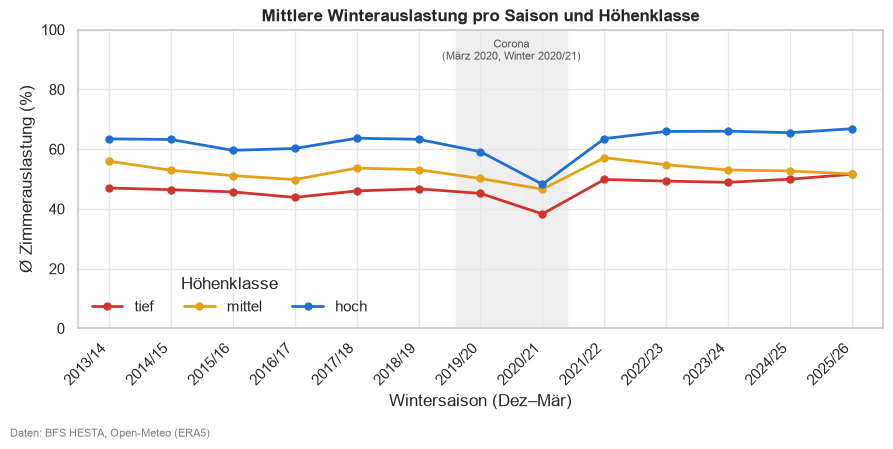

In [23]:
saison = (panel.groupby(["winter", "winter_label", "hoehenklasse"])["zimmerauslastung"].mean()
          .unstack("hoehenklasse")[KLASSEN].reset_index())

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(saison))
cov = x[saison.winter.isin([2019, 2020]).to_numpy()]
ax.axvspan(cov.min() - 0.4, cov.max() + 0.4, color="#eeeeee", zorder=0)
ax.text(cov.mean(), 97, "Corona\n(März 2020, Winter 2020/21)", ha="center", va="top", fontsize=8, color="#555555")
for k in KLASSEN:
    ax.plot(x, saison[k], color=FARBEN[k], linewidth=2, marker="o", markersize=5, label=k)
ax.set_xticks(x, saison.winter_label, rotation=45, ha="right")
ax.set(ylim=(0, 100), xlim=(-0.5, len(x) - 0.5), xlabel="Wintersaison (Dez–Mär)",
       ylabel="Ø Zimmerauslastung (%)", title="Mittlere Winterauslastung pro Saison und Höhenklasse")
ax.legend(title="Höhenklasse", loc="lower left", ncols=3, frameon=False)
speichern(fig, "linie_saison_hoehe")
plt.show()

Die drei Linien verlaufen fast parallel. Ausserhalb von Corona liegen die hohen Orte in jedem Winter rund 14–17 pp über den tiefen. Der Abstand ist also stabil und kein Effekt einzelner Winter. Corona ist deutlich sichtbar: 2019/20 drückt der Lockdown-März den Schnitt, 2020/21 bricht die Auslastung in allen Klassen ein. Danach erholt sie sich rasch und liegt bei «tief» und «hoch» sogar leicht über dem Niveau vor Corona. Einen Abwärtstrend der tiefen Orte, etwa wegen schlechterer Schneelage, zeigt dieser Zeitraum nicht. 2025/26 liegen tief und mittel gleichauf.

### 2.4 Schneefall und Auslastung: roh und bereinigt

Bereinigt heisst wie in Teil 3.4: Von Schneefall und Auslastung wird der Mittelwert derselben Gemeinde im selben Kalendermonat abgezogen (`schnee_abw`, `ausl_abw`, gleiche Definition wie in Teil 3).

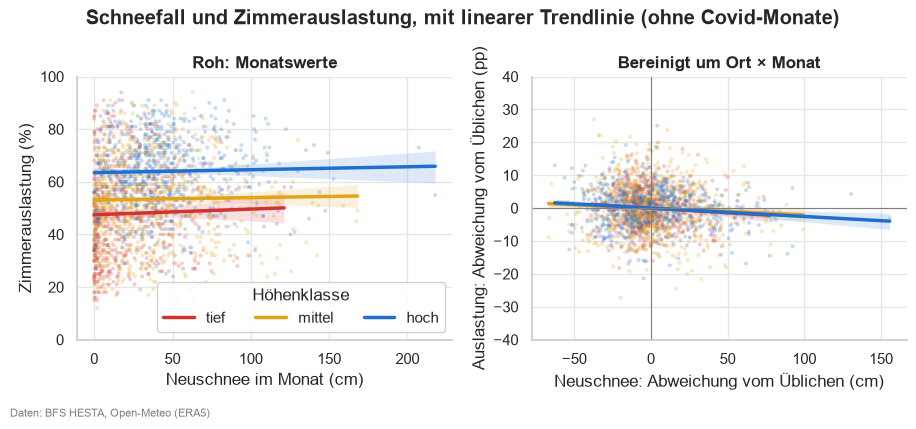

In [24]:
d["schnee_abw"] = d.schneefall_cm - d.groupby(["bfs_nr", "monat"]).schneefall_cm.transform("mean")
d["ausl_abw"] = d.zimmerauslastung - d.groupby(["bfs_nr", "monat"]).zimmerauslastung.transform("mean")

lang = pd.concat([
    d.assign(Variante="Roh: Monatswerte", x=d.schneefall_cm, y=d.zimmerauslastung),
    d.assign(Variante="Bereinigt um Ort × Monat", x=d.schnee_abw, y=d.ausl_abw),
])[["Variante", "hoehenklasse", "x", "y"]]

g = sns.lmplot(data=lang, x="x", y="y", hue="hoehenklasse", hue_order=KLASSEN, palette=FARBEN,
               col="Variante", facet_kws={"sharex": False, "sharey": False}, height=4.2, aspect=1.1,
               scatter_kws={"s": 8, "alpha": 0.25, "edgecolor": "none"}, line_kws={"linewidth": 2.5}, legend=False)
g.set_titles("{col_name}")
g.axes[0, 0].set(xlabel="Neuschnee im Monat (cm)", ylabel="Zimmerauslastung (%)", ylim=(0, 100))
g.axes[0, 1].set(xlabel="Neuschnee: Abweichung vom Üblichen (cm)",
                 ylabel="Auslastung: Abweichung vom Üblichen (pp)", ylim=(-40, 40))
g.axes[0, 1].axhline(0, color="grey", linewidth=0.8); g.axes[0, 1].axvline(0, color="grey", linewidth=0.8)
g.axes[0, 0].legend(handles=[mpl.lines.Line2D([], [], color=FARBEN[k], linewidth=2.5, label=k) for k in KLASSEN],
                    title="Höhenklasse", loc="lower right", ncols=3, frameon=True, framealpha=0.9)
g.figure.suptitle("Schneefall und Zimmerauslastung, mit linearer Trendlinie (ohne Covid-Monate)", fontweight="bold")
speichern(g.figure, "streu_schnee_auslastung")
plt.show()

**Links (roh)** steigen alle drei Linien leicht an: Mehr Schnee scheint mit mehr Gästen einherzugehen. Ein Teil davon ist aber Kalender: Im Januar und Februar fällt viel Schnee und es kommen viele Gäste, im Dezember und März beides weniger. **Rechts (bereinigt)** ist dieser Effekt herausgerechnet. Die Linien liegen flach bis leicht fallend, am deutlichsten bei den hohen Orten: Schneit es in einem Monat mehr als dort üblich, ist die Auslastung nicht höher. Darum kippt das Vorzeichen in Teil 3.4. Die Punktwolken zeigen auch, wie schwach der Zusammenhang ist (|r| ≤ 0.11). Der Schneefall eines einzelnen Monats erklärt fast nichts.

### 2.5 Heatmap Monat × Winter

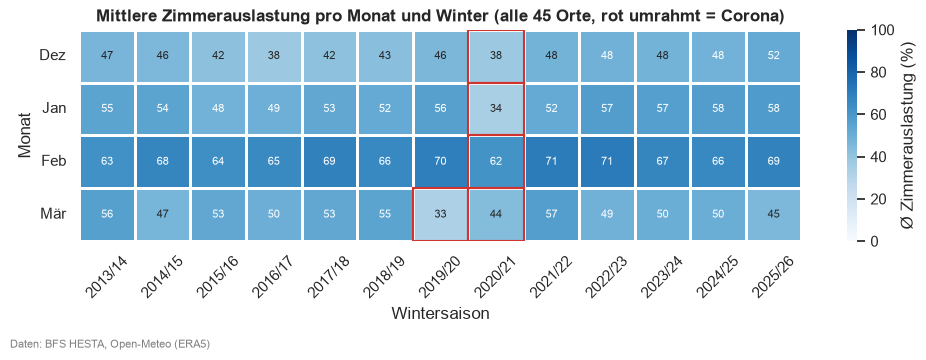

In [25]:
hm = (panel.pivot_table(index="monat", columns="winter_label", values="zimmerauslastung", aggfunc="mean")
      .reindex(list(MONATE)))
hm.index = hm.index.map(MONATE)

fig, ax = plt.subplots(figsize=(10, 3.6))
sns.heatmap(hm, cmap="Blues", vmin=0, vmax=100, annot=True, fmt=".0f", annot_kws={"fontsize": 8},
            linewidths=2, linecolor="white", cbar_kws={"label": "Ø Zimmerauslastung (%)"}, ax=ax)
# Corona-Monate umrahmen
for (j, w) in enumerate(hm.columns):
    for (i, m) in enumerate(hm.index):
        if w == "2020/21" or (w == "2019/20" and m == "Mär"):
            ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="#d1342f", linewidth=1.5))
ax.set(xlabel="Wintersaison", ylabel="Monat",
       title="Mittlere Zimmerauslastung pro Monat und Winter (alle 45 Orte, rot umrahmt = Corona)")
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)
speichern(fig, "heatmap_monat_winter")
plt.show()

Das Muster ist in fast allen Wintern gleich: Der Februar ist am dunkelsten, Dezember und März am hellsten. Das Saisonmuster ist also stabiler als die Unterschiede zwischen den Jahren. Der Lockdown im März 2020 ergibt die hellste Zelle der Tabelle (33 %), knapp vor dem Januar 2021 (34 %). Auffällig ist ausserdem der Dezember: Er steigt von 38–43 % (2015/16–2018/19) auf 48–52 % seit 2021/22, die Saison beginnt also besser ausgelastet. Andere Ausreisserwinter mit auffällig schwacher Auslastung (z. B. wegen Schneemangel) sind nicht zu erkennen.

## Teil 3: Statistische Tests

**Fragen:** (a) Unterscheidet sich die mittlere Winter-Zimmerauslastung zwischen den Höhenklassen? (b) Hängt Schneefall mit der Auslastung zusammen?

**Lesehilfe:** p < 0.05 heisst, ein Unterschied (bzw. Zusammenhang) dieser Grösse wäre ohne echten Unterschied unwahrscheinlich. Signifikant heisst nicht wichtig, darum steht immer auch die Grösse in Prozentpunkten (pp) dabei.

### 3.1 Eine Beobachtung pro Gemeinde

Die ANOVA verlangt unabhängige Beobachtungen. Dieselbe Gemeinde in rund 45 Wintermonaten ist nicht unabhängig, darum zuerst pro Gemeinde über alle Winter (ohne Covid) mitteln. Danach gibt es 45 Werte: 13 tief / 19 mittel / 13 hoch.

In [26]:
pro_gem = (d.groupby(["bfs_nr", "name", "hoehenklasse", "hoehenklasse_1000"])["zimmerauslastung"]
           .mean().reset_index())
gruppen = [pro_gem.loc[pro_gem.hoehenklasse == k, "zimmerauslastung"] for k in KLASSEN]

beschr = (pro_gem.groupby("hoehenklasse")["zimmerauslastung"]
          .agg(Orte="count", Mittel="mean", Median="median", Std="std").reindex(KLASSEN).round(1))
beschr

,Orte,Mittel,Median,Std
hoehenklasse,,,,
tief,13,47.9,46.2,14.1
mittel,19,53.0,55.4,10.7
hoch,13,64.0,65.9,9.6


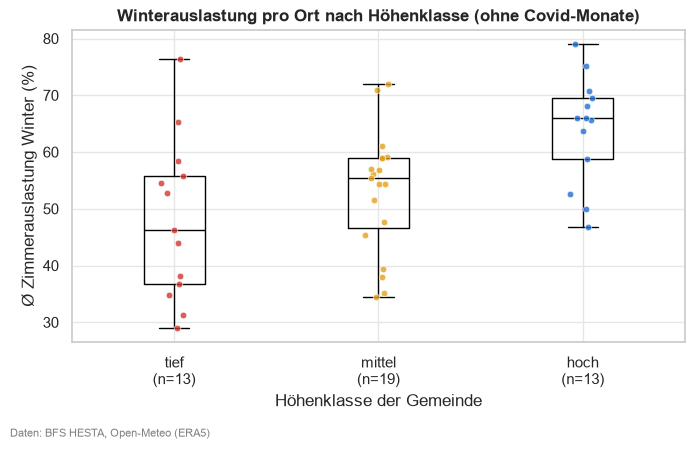

In [27]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot(gruppen, showfliers=False, medianprops={"color": "black"})
for i, (k, g) in enumerate(zip(KLASSEN, gruppen), start=1):
    ax.scatter(np.random.default_rng(1).normal(i, 0.05, len(g)), g, s=22, alpha=0.8,
               color=FARBEN[k], edgecolor="white", linewidth=0.5, zorder=3)
ax.set_xticks([1, 2, 3], [f"{k}\n(n={len(g)})" for k, g in zip(KLASSEN, gruppen)])
ax.set(xlabel="Höhenklasse der Gemeinde", ylabel="Ø Zimmerauslastung Winter (%)",
       title="Winterauslastung pro Ort nach Höhenklasse (ohne Covid-Monate)")
speichern(fig, "box_auslastung_hoehe")
plt.show()


### 3.2 Levene, ANOVA, Kruskal-Wallis

In [28]:
levene = stats.levene(*gruppen)
anova = stats.f_oneway(*gruppen)
kruskal = stats.kruskal(*gruppen)

n = len(pro_gem)
gesamt = pro_gem.zimmerauslastung
eta2 = sum(len(g) * (g.mean() - gesamt.mean()) ** 2 for g in gruppen) / ((gesamt - gesamt.mean()) ** 2).sum()
eps2 = kruskal.statistic / (n - 1)   # Effektstärke Kruskal-Wallis

print(f"Levene:          W = {levene.statistic:.2f}, p = {levene.pvalue:.3f}")
print(f"ANOVA:           F = {anova.statistic:.2f}, p = {anova.pvalue:.4f}, eta² = {eta2:.2f}")
print(f"Kruskal-Wallis:  H = {kruskal.statistic:.2f}, p = {kruskal.pvalue:.4f}, epsilon² = {eps2:.2f}")

Levene:          W = 1.42, p = 0.253
ANOVA:           F = 6.68, p = 0.0030, eta² = 0.24
Kruskal-Wallis:  H = 10.25, p = 0.0060, epsilon² = 0.23


Levene ist nicht signifikant, die Annahme gleicher Varianzen hält also, und die klassische ANOVA ist zulässig. Weil die Gruppen klein sind (13 / 19 / 13), wird Kruskal-Wallis (rangbasiert, ohne Normalverteilungsannahme) gleich gewichtig berichtet.

### 3.3 Post-hoc: Tukey HSD

Welche Klassen unterscheiden sich? Tukey korrigiert für die drei Paarvergleiche.

In [29]:
tukey = pairwise_tukeyhsd(pro_gem.zimmerauslastung, pro_gem.hoehenklasse, alpha=0.05)
tk = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])
tk

,group1,group2,meandiff,p-adj,lower,upper,reject
0,hoch,mittel,-11.0067,0.0293,-21.0740,-0.9395,True
1,hoch,tief,-16.0472,0.0027,-27.0177,-5.0767,True
2,mittel,tief,-5.0405,0.4503,-15.1077,5.0268,False


### 3.4 Spearman: Schneefall und Auslastung pro Höhenklasse

Zwei Varianten:

1. **Roh:** Monatswerte direkt korreliert (wie in der Vorlage). Problem: Saison. Januar hat am meisten Schnee, Februar die höchste Auslastung (Sportferien). Damit misst die Korrelation zum Teil nur den Kalender.
2. **Bereinigt:** Von Schneefall und Auslastung wird jeweils der Mittelwert derselben Gemeinde im selben Kalendermonat abgezogen. Übrig bleibt: «Mehr Schnee als in diesem Ort in diesem Monat üblich» vs. «Auslastung höher als üblich».

Auch hier sind die Monatswerte nicht unabhängig (gleiche Gemeinde, gleicher Winter), die p-Werte sind darum eher zu optimistisch.

In [30]:
d["schnee_abw"] = d.schneefall_cm - d.groupby(["bfs_nr", "monat"]).schneefall_cm.transform("mean")
d["ausl_abw"] = d.zimmerauslastung - d.groupby(["bfs_nr", "monat"]).zimmerauslastung.transform("mean")

kor = []
for k in KLASSEN:
    x = d[d.hoehenklasse == k]
    r1, p1 = stats.spearmanr(x.schneefall_cm, x.zimmerauslastung)
    r2, p2 = stats.spearmanr(x.schnee_abw, x.ausl_abw)
    kor.append({"Höhenklasse": k, "n": len(x), "r roh": r1, "p roh": p1, "r bereinigt": r2, "p bereinigt": p2})
kor = pd.DataFrame(kor).round(4)
kor

,Höhenklasse,n,r roh,p roh,r bereinigt,p bereinigt
0,tief,611,0.1067,0.0083,-0.0985,0.0148
1,mittel,850,0.0704,0.0402,-0.0489,0.1542
2,hoch,571,0.0602,0.1505,-0.0838,0.0454


### 3.5 Robustheit: Grenze bei 1000 m (`hoehenklasse_1000`)

Mit der 1000-m-Grenze hat «tief» nur 3 Orte. Dort wird kein Test gerechnet, nur beschreibend gezeigt.

In [31]:
(pro_gem.groupby("hoehenklasse_1000")["zimmerauslastung"]
 .agg(Orte="count", Mittel="mean", Median="median", Min="min", Max="max")
 .reindex(KLASSEN).round(1))

,Orte,Mittel,Median,Min,Max
hoehenklasse_1000,,,,,
tief,3,35.4,36.7,31.4,38.1
mittel,29,52.5,54.6,29.0,76.4
hoch,13,64.0,65.9,46.9,79.1


### 3.6 Ergebnistabelle

In [32]:
m = beschr["Mittel"]
def pp(a, b):
    row = tk[((tk.group1 == a) & (tk.group2 == b)) | ((tk.group1 == b) & (tk.group2 == a))].iloc[0]
    return row["p-adj"]

def sig(p):
    return "signifikant" if p < 0.05 else "nicht signifikant"

def stark(p, r):
    return f"{sig(p)}{', aber' if p < 0.05 else ','} sehr schwach (|r| ≈ {abs(r):.2f})"

ergebnis = pd.DataFrame([
    ["Levene (gleiche Varianzen)", f"W = {levene.statistic:.2f}", levene.pvalue,
     f"{sig(levene.pvalue)}: Varianzen gleich genug, klassische ANOVA zulässig"],
    ["ANOVA Höhenklassen", f"F = {anova.statistic:.2f}, η² = {eta2:.2f}", anova.pvalue,
     f"{sig(anova.pvalue)}: Mittel tief {m['tief']:.1f} %, mittel {m['mittel']:.1f} %, hoch {m['hoch']:.1f} %. "
     f"Höhenklasse erklärt rund {eta2:.0%} der Unterschiede zwischen den Orten"],
    ["Kruskal-Wallis Höhenklassen", f"H = {kruskal.statistic:.2f}, ε² = {eps2:.2f}", kruskal.pvalue,
     f"{sig(kruskal.pvalue)}: bestätigt die ANOVA ohne Normalverteilungsannahme"],
    ["Tukey hoch – tief", f"Δ = {m['hoch'] - m['tief']:+.1f} pp", pp("hoch", "tief"),
     f"{sig(pp('hoch', 'tief'))}: hohe Orte {m['hoch'] - m['tief']:.1f} pp besser ausgelastet"],
    ["Tukey hoch – mittel", f"Δ = {m['hoch'] - m['mittel']:+.1f} pp", pp("hoch", "mittel"),
     f"{sig(pp('hoch', 'mittel'))}: hohe Orte {m['hoch'] - m['mittel']:.1f} pp besser ausgelastet"],
    ["Tukey mittel – tief", f"Δ = {m['mittel'] - m['tief']:+.1f} pp", pp("mittel", "tief"),
     f"{sig(pp('mittel', 'tief'))}: Unterschied von {m['mittel'] - m['tief']:.1f} pp mit 13 / 19 Orten nicht sicher von Zufall zu trennen"],
] + [
    [f"Spearman Schnee–Auslastung {r['Höhenklasse']} (roh)", f"r = {r['r roh']:.2f}, n = {r['n']}", r["p roh"],
     stark(r["p roh"], r["r roh"])]
    for _, r in kor.iterrows()
] + [
    [f"Spearman Schnee–Auslastung {r['Höhenklasse']} (bereinigt)", f"r = {r['r bereinigt']:.2f}, n = {r['n']}", r["p bereinigt"],
     stark(r["p bereinigt"], r["r bereinigt"])]
    for _, r in kor.iterrows()
], columns=["Test", "Statistik", "p-Wert", "Interpretation"])
ergebnis["p-Wert"] = ergebnis["p-Wert"].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")
ergebnis

,Test,Statistik,p-Wert,Interpretation
0,Levene (gleiche Varianzen),W = 1.42,0.253,"nicht signifikant: Varianzen gleich genug, klassische ANOVA zulässig"
1,ANOVA Höhenklassen,"F = 6.68, η² = 0.24",0.003,"signifikant: Mittel tief 47.9 %, mittel 53.0 %, hoch 64.0 %. Höhenklasse erklärt rund 24% der Unterschiede zwischen den Orten"
2,Kruskal-Wallis Höhenklassen,"H = 10.25, ε² = 0.23",0.006,signifikant: bestätigt die ANOVA ohne Normalverteilungsannahme
3,Tukey hoch – tief,Δ = +16.1 pp,0.003,signifikant: hohe Orte 16.1 pp besser ausgelastet
4,Tukey hoch – mittel,Δ = +11.0 pp,0.029,signifikant: hohe Orte 11.0 pp besser ausgelastet
5,Tukey mittel – tief,Δ = +5.1 pp,0.450,nicht signifikant: Unterschied von 5.1 pp mit 13 / 19 Orten nicht sicher von Zufall zu trennen
6,Spearman Schnee–Auslastung tief (roh),"r = 0.11, n = 611",0.008,"signifikant, aber sehr schwach (|r| ≈ 0.11)"
7,Spearman Schnee–Auslastung mittel (roh),"r = 0.07, n = 850",0.040,"signifikant, aber sehr schwach (|r| ≈ 0.07)"
8,Spearman Schnee–Auslastung hoch (roh),"r = 0.06, n = 571",0.150,"nicht signifikant, sehr schwach (|r| ≈ 0.06)"
9,Spearman Schnee–Auslastung tief (bereinigt),"r = -0.10, n = 611",0.015,"signifikant, aber sehr schwach (|r| ≈ 0.10)"


### 3.7 Interpretation

**Höhenklassen:** Die Winter-Zimmerauslastung unterscheidet sich zwischen den Höhenklassen. ANOVA und Kruskal-Wallis sind beide signifikant (p < 0.01). Der Unterschied ist auch inhaltlich gross: Hohe Orte (über 1500 m) sind im Winter im Mittel rund 16 pp besser ausgelastet als tiefe (unter 1200 m) und rund 11 pp besser als mittlere. Zwischen tief und mittel liegen rund 5 pp, das ist mit den kleinen Gruppen nicht signifikant. Die Höhenklasse erklärt etwa ein Viertel der Unterschiede zwischen den Orten (η²), der Rest liegt an anderem (Grösse, Bekanntheit, Erreichbarkeit usw.).

**Schnee und Auslastung:** Roh hängt mehr Schneefall in tiefen und mittleren Orten minimal positiv mit der Auslastung zusammen, aber dieser Effekt ist teilweise nur Saison (Kalendermonat). Bereinigt um Ort und Monat dreht das Vorzeichen leicht ins Negative: In Monaten mit mehr Schnee als üblich ist die Auslastung nicht höher, sondern eher minimal tiefer. Mögliche Gründe sind, dass Gäste lange im Voraus buchen oder dass bei starkem Schneefall Strassen und Anlagen gesperrt sind. Alle Korrelationen sind sehr schwach (|r| ≤ 0.11), Schneefall im selben Monat erklärt also praktisch nichts von der Auslastung. Wichtiger ist die Höhenlage als dauerhafte Eigenschaft (Schneesicherheit über die Jahre) als der Schneefall im einzelnen Monat.

**Korrelation beweist keine Ursache.** Die Tests zeigen Zusammenhänge, keine Wirkung. Ob Schnee die Auslastung beeinflusst, prüft die Regression (5.x) mit Kontrollvariablen.

**Robustheit 1000-m-Grenze:** Mit der 1000-m-Grenze hat «tief» nur 3 Orte, darum dort nur beschreibend. Die Reihenfolge tief < mittel < hoch bleibt gleich (siehe 3.5).

## Teil 4: Karten (4.3)

Gemeindegrenzen (1.6) werden mit der mittleren Winter-Zimmerauslastung aus dem Panel (3.2) verknüpft.

- Mittelwert über alle Wintermonate (Dez–Mär) 2013/14–2025/26 **ohne Covid-Monate** (`covid == 0`)
- Alle Schweizer Gemeinden grau, die 45 Wintersportorte farbig
- Viele Orte sind klein, darum zusätzlich Punkte (Koordinaten aus `gemeinden.csv`), Grösse = Ø Betten

Produkte: `figures/karte_auslastung.png` (statisch, Folien) und `figures/karte_interaktiv.html` (Folium, Bonus).

In [33]:
geo = gpd.read_file("../data/processed/gemeinden.geojson")
gem = pd.read_csv("../data/processed/gemeinden.csv")
print(panel.bfs_nr.nunique(), "Orte im Panel,", len(geo), "Gemeinden in der Geometrie")

45 Orte im Panel, 2111 Gemeinden in der Geometrie


### Verknüpfen

In [34]:
mittel = (panel[panel.covid == 0]
          .groupby("bfs_nr")
          .agg(auslastung=("zimmerauslastung", "mean"), betten=("betten", "mean"))
          .reset_index())

karte = geo.merge(mittel, on="bfs_nr", how="left")   # nur die 45 Orte haben einen Wert
orte = (mittel.merge(gem[["bfs_nr", "name", "kanton", "lat", "lon", "hoehe_m", "hoehenklasse"]],
                     on="bfs_nr", how="left"))
orte = gpd.GeoDataFrame(orte, geometry=gpd.points_from_xy(orte.lon, orte.lat), crs="EPSG:4326")

# Kontrolle: alle 45 Orte gefunden (Geometrie und Koordinaten)
assert karte.auslastung.notna().sum() == 45, karte.auslastung.notna().sum()
assert orte.lat.notna().all() and len(orte) == 45
orte[["auslastung", "betten"]].describe().round(1)

,auslastung,betten
count,45.0,45.0
mean,54.7,1516.5
std,12.9,1579.0
min,29.0,187.3
25%,46.2,500.6
50%,55.8,1124.0
75%,65.2,1767.1
max,79.1,7308.9


### Statische Karte (Folien)

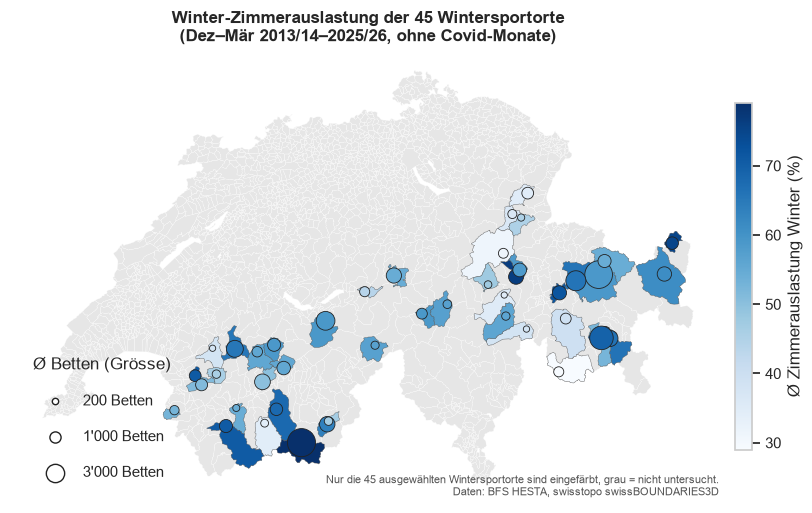

In [35]:
# Projektion LV95, damit die Schweiz nicht gestaucht aussieht
karte_lv = karte.to_crs(2056)
orte_lv = orte.to_crs(2056)

norm = mpl.colors.Normalize(vmin=orte.auslastung.min(), vmax=orte.auslastung.max())
cmap = plt.get_cmap("Blues")

def groesse(betten):
    return betten / orte.betten.max() * 400 + 10   # Fläche der Punkte ~ Betten

fig, ax = plt.subplots(figsize=(11, 7.5))
karte_lv.plot(ax=ax, color="#e6e6e6", edgecolor="white", linewidth=0.2)
karte_lv.dropna(subset=["auslastung"]).plot(ax=ax, column="auslastung", cmap=cmap, norm=norm,
                                            edgecolor="#555555", linewidth=0.3)
ax.scatter(orte_lv.geometry.x, orte_lv.geometry.y, s=groesse(orte_lv.betten),
           c=orte_lv.auslastung, cmap=cmap, norm=norm, edgecolor="#222222", linewidth=0.6, zorder=3)

# Farblegende
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.6, pad=0.01)
cb.set_label("Ø Zimmerauslastung Winter (%)")

# Grössenlegende
for b in [200, 1000, 3000]:
    ax.scatter([], [], s=groesse(b), color="white", edgecolor="#222222", label=f"{b:,} Betten".replace(",", "'"))
ax.legend(title="Ø Betten (Grösse)", loc="lower left", frameon=False, labelspacing=1.4, borderpad=1)

ax.set_title("Winter-Zimmerauslastung der 45 Wintersportorte\n(Dez–Mär 2013/14–2025/26, ohne Covid-Monate)")
ax.text(0.99, 0.01, "Nur die 45 ausgewählten Wintersportorte sind eingefärbt, grau = nicht untersucht.\n"
        "Daten: BFS HESTA, swisstopo swissBOUNDARIES3D",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color="#555555")
ax.set_axis_off()
fig.savefig("../figures/karte_auslastung.png", dpi=200, bbox_inches="tight")
plt.show()

### Interaktive Karte (Bonus)

In [36]:
# Hintergrund: graue Landeskarte swisstopo (frei, ohne API-Key; CartoDB verlangt neu einen Key)
m = folium.Map(location=[46.8, 8.2], zoom_start=8,
               tiles="https://wmts.geo.admin.ch/1.0.0/ch.swisstopo.pixelkarte-grau/default/current/3857/{z}/{x}/{y}.jpeg",
               attr="© swisstopo")

# Alle Gemeinden grau (vereinfacht, damit die HTML-Datei klein bleibt)
grau = karte[["bfs_nr", "name", "geometry"]].copy()
grau["geometry"] = grau.geometry.simplify(0.002, preserve_topology=True)
folium.GeoJson(grau, name="Alle Gemeinden (nicht untersucht)",
               style_function=lambda f: {"fillColor": "#e6e6e6", "color": "white", "weight": 0.3, "fillOpacity": 0.6},
               tooltip=folium.GeoJsonTooltip(["name"], aliases=["Gemeinde"])).add_to(m)

# 45 Wintersportorte eingefärbt
orte_poly = karte.dropna(subset=["auslastung"]).copy()
orte_poly["auslastung"] = orte_poly.auslastung.round(1)
folium.Choropleth(geo_data=orte_poly, data=orte_poly, columns=["bfs_nr", "auslastung"],
                  key_on="feature.properties.bfs_nr", fill_color="Blues", fill_opacity=0.85,
                  line_weight=0.5, name="Wintersportorte (Fläche)",
                  legend_name="Ø Zimmerauslastung Winter (%)").add_to(m)

# Punkte, Grösse = Betten, mit Infos
punkte = folium.FeatureGroup(name="Wintersportorte (Punkte, Grösse = Betten)")
for _, r in orte.iterrows():
    folium.CircleMarker(
        location=[r.lat, r.lon], radius=(r.betten / orte.betten.max()) ** 0.5 * 18 + 3,
        color="#222222", weight=1, fill=True, fill_color=mpl.colors.to_hex(cmap(norm(r.auslastung))), fill_opacity=0.9,
        tooltip=(f"<b>{r['name']}</b> ({r.kanton})<br>"
                 f"Ø Zimmerauslastung Winter: {r.auslastung:.1f} %<br>"
                 f"Ø Betten: {r.betten:,.0f}<br>".replace(",", "'") +
                 f"Höhe: {r.hoehe_m:.0f} m ({r.hoehenklasse})")
    ).add_to(punkte)
punkte.add_to(m)

hinweis = ('<div style="position:fixed;bottom:20px;left:20px;z-index:9999;background:white;padding:6px 10px;'
           'border:1px solid #999;font-size:12px;max-width:320px">'
           '<b>Winter-Zimmerauslastung der 45 Wintersportorte</b><br>'
           'Dez–Mär 2013/14–2025/26, ohne Covid-Monate.<br>'
           'Nur die 45 ausgewählten Wintersportorte sind eingefärbt, grau = nicht untersucht. '
           'Punktgrösse = Ø Betten.</div>')
m.get_root().html.add_child(folium.Element(hinweis))
folium.LayerControl(collapsed=False).add_to(m)
m.save("../figures/karte_interaktiv.html")

print(f"{os.path.getsize('../figures/karte_interaktiv.html') / 1e6:.1f} MB")

2.4 MB
